In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# display all columns when viewing dataframes
pd.set_option('display.max_columns', None)

# set simple plot style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# make folders if they don't already exist
os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/intermediate', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)

# check where the raw dataset file is located
raw_file = 'dft-road-casualty-statistics-collision-1979-latest-published-year.csv'
if not os.path.exists(raw_file):
    raw_file = os.path.join('data', 'raw', raw_file)

print("Raw file path:", os.path.abspath(raw_file))
print(f"File size: {os.path.getsize(raw_file) / (1024**3):.2f} GB")

Raw file path: C:\Users\Shrinivas\Desktop\road-accident-severity-prediction\dft-road-casualty-statistics-collision-1979-latest-published-year.csv
File size: 1.43 GB


In [3]:
# read in chunks of 500k rows to get yearly counts
yearly_total = {}
yearly_fatal = {}

print("Reading raw file in chunks...")
for chunk in pd.read_csv(raw_file, usecols=['collision_year', 'collision_severity'], chunksize=500000, low_memory=False):
    # count total accidents per year
    for yr, count in chunk['collision_year'].value_counts().items():
        yearly_total[yr] = yearly_total.get(yr, 0) + count
        
    # count fatal accidents (severity == 1)
    fatals = chunk[chunk['collision_severity'] == 1]
    for yr, count in fatals['collision_year'].value_counts().items():
        yearly_fatal[yr] = yearly_fatal.get(yr, 0) + count

# put into a dataframe to look at it
df_history = pd.DataFrame({
    'total_accidents': pd.Series(yearly_total),
    'fatal_accidents': pd.Series(yearly_fatal)
}).sort_index()

df_history['fatal_rate_pct'] = (df_history['fatal_accidents'] / df_history['total_accidents']) * 100

print("Finished reading!")
print(f"Total historical records: {df_history['total_accidents'].sum():,}")
print(f"Peak accident year: {df_history['total_accidents'].idxmax()} ({df_history['total_accidents'].max():,} accidents)")
print(f"Accidents in 2023: {df_history.loc[2023, 'total_accidents']:,}")
df_history.tail(10)

Reading raw file in chunks...


Finished reading!
Total historical records: 9,116,625
Peak accident year: 1989 (260,759 accidents)
Accidents in 2023: 104,258


,total_accidents,fatal_accidents,fatal_rate_pct
2016,136621,1695,1.240658
2017,129982,1676,1.289409
2018,122635,1671,1.362580
2019,117536,1658,1.410632
2020,91199,1391,1.525236
2021,101087,1474,1.458150
2022,106004,1602,1.511264
2023,104258,1522,1.459840
2024,100927,1502,1.488204
2025,101525,1453,1.431175


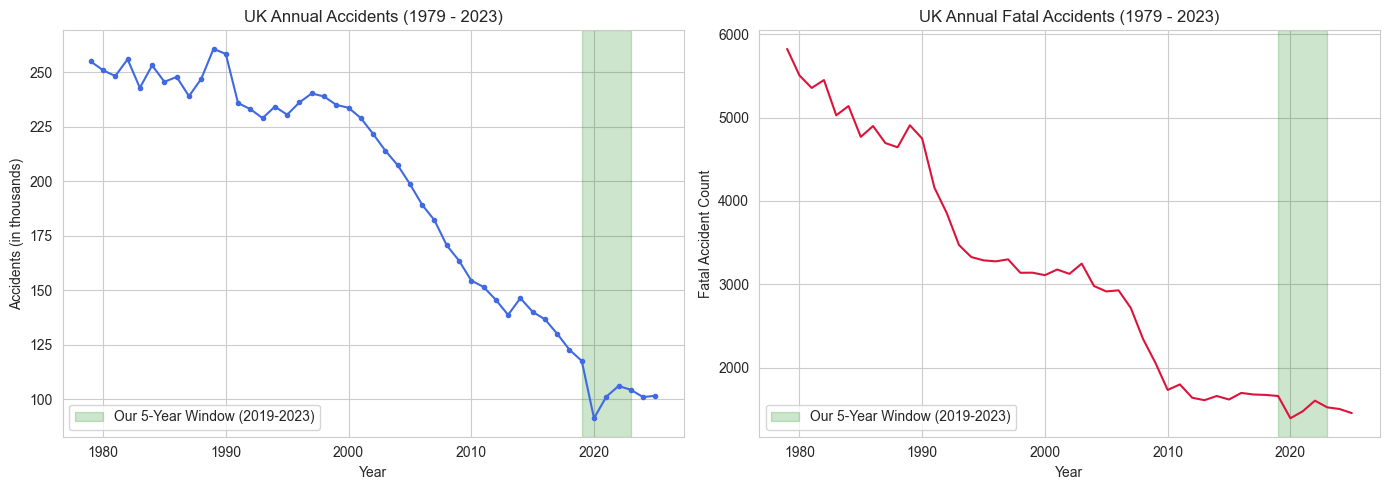

In [4]:
plt.figure(figsize=(14, 5))

# Plot 1: Total accidents
plt.subplot(1, 2, 1)
plt.plot(df_history.index, df_history['total_accidents'] / 1000, color='royalblue', marker='o', markersize=3)
plt.title('UK Annual Accidents (1979 - 2023)')
plt.xlabel('Year')
plt.ylabel('Accidents (in thousands)')
plt.axvspan(2019, 2023, color='green', alpha=0.2, label='Our 5-Year Window (2019-2023)')
plt.legend()

# Plot 2: Fatal accidents
plt.subplot(1, 2, 2)
plt.plot(df_history.index, df_history['fatal_accidents'], color='crimson')
plt.title('UK Annual Fatal Accidents (1979 - 2023)')
plt.xlabel('Year')
plt.ylabel('Fatal Accident Count')
plt.axvspan(2019, 2023, color='green', alpha=0.2, label='Our 5-Year Window (2019-2023)')
plt.legend()

plt.tight_layout()
plt.show()

In [5]:
# list of columns we want to extract
selected_columns = [
    'collision_index', 'collision_ref_no', 'collision_year', 'collision_severity',
    'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time',
    'local_authority_district', 'local_authority_ons_district', 'local_authority_highway',
    'first_road_class', 'first_road_number', 'road_type', 'speed_limit',
    'junction_detail', 'junction_control', 'second_road_class', 'second_road_number',
    'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic',
    'light_conditions', 'weather_conditions', 'road_surface_conditions',
    'special_conditions_at_site', 'carriageway_hazards', 'urban_or_rural_area',
    'did_police_officer_attend_scene_of_accident', 'trunk_road_flag',
    'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude',
    'police_force', 'pedestrian_crossing', 'special_conditions_at_site_historic',
    'carriageway_hazards_historic', 'local_authority_highway_current',
    'junction_detail_historic', 'lsoa_of_accident_location', 'enhanced_severity_collision',
    'collision_injury_based', 'collision_adjusted_severity_serious', 'collision_adjusted_severity_slight'
]

# extract chunk by chunk
staging_file = 'data/intermediate/staged_raw_2019_2023.csv'
chunks = []

print("Extracting 2019-2023 data...")
for chunk in pd.read_csv(raw_file, chunksize=500000, low_memory=False):
    # filter columns that are in the file
    available_cols = [c for c in selected_columns if c in chunk.columns]
    sub = chunk[available_cols]
    
    # filter rows where collision_year is between 2019 and 2023
    sub_5yr = sub[(sub['collision_year'] >= 2019) & (sub['collision_year'] <= 2023)]
    if len(sub_5yr) > 0:
        chunks.append(sub_5yr)

# combine all chunks
df_5yr = pd.concat(chunks, ignore_index=True)

# save to intermediate staging file
df_5yr.to_csv(staging_file, index=False)

print("Extraction complete!")
print("Dataset shape:", df_5yr.shape)

Extracting 2019-2023 data...


Extraction complete!
Dataset shape: (520084, 44)


In [6]:
# count accidents by year
year_counts = df_5yr['collision_year'].value_counts().sort_index()
year_pcts = (year_counts / len(df_5yr)) * 100

summary_years = pd.DataFrame({
    'accident_count': year_counts,
    'percentage': year_pcts
})
print("Accident breakdown by year:")
print(summary_years)
print(f"\nTotal rows in 5-year data: {len(df_5yr):,}")

Accident breakdown by year:
                accident_count  percentage
collision_year                            
2019                    117536   22.599426
2020                     91199   17.535437
2021                    101087   19.436668
2022                    106004   20.382092
2023                    104258   20.046377

Total rows in 5-year data: 520,084


In [7]:
# standard missing values check
null_counts = df_5yr.isnull().sum()
cols_with_nulls = null_counts[null_counts > 0]

print(f"Number of columns with standard null values: {len(cols_with_nulls)}")
print(cols_with_nulls)

Number of columns with standard null values: 4
location_easting_osgr     93
location_northing_osgr    93
longitude                 93
latitude                  93
dtype: int64


In [8]:
# count how many times -1 appears in each column
neg_ones = (df_5yr == -1).sum()

# combine standard nulls and -1 counts
missing_audit = pd.DataFrame({
    'null_count': null_counts,
    'minus_one_count': neg_ones,
    'total_missing': null_counts + neg_ones
})
missing_audit['missing_pct'] = (missing_audit['total_missing'] / len(df_5yr)) * 100

# show top columns with the most missing values
top_missing = missing_audit[missing_audit['total_missing'] > 0].sort_values(by='total_missing', ascending=False)
print("Top 15 columns with missing / -1 values:")
print(top_missing.head(15))

Top 15 columns with missing / -1 values:
                                                  null_count  minus_one_count  \
local_authority_district                                   0           312146   
enhanced_severity_collision                                0           267717   
junction_control                                           0           218493   
second_road_number                                         0           216129   
trunk_road_flag                                            0            38841   
junction_detail                                            0             9183   
special_conditions_at_site                                 0             4671   
carriageway_hazards_historic                               0             4653   
carriageway_hazards                                        0             4517   
pedestrian_crossing_human_control_historic                 0             4043   
pedestrian_crossing_physical_facilities_historic           0        

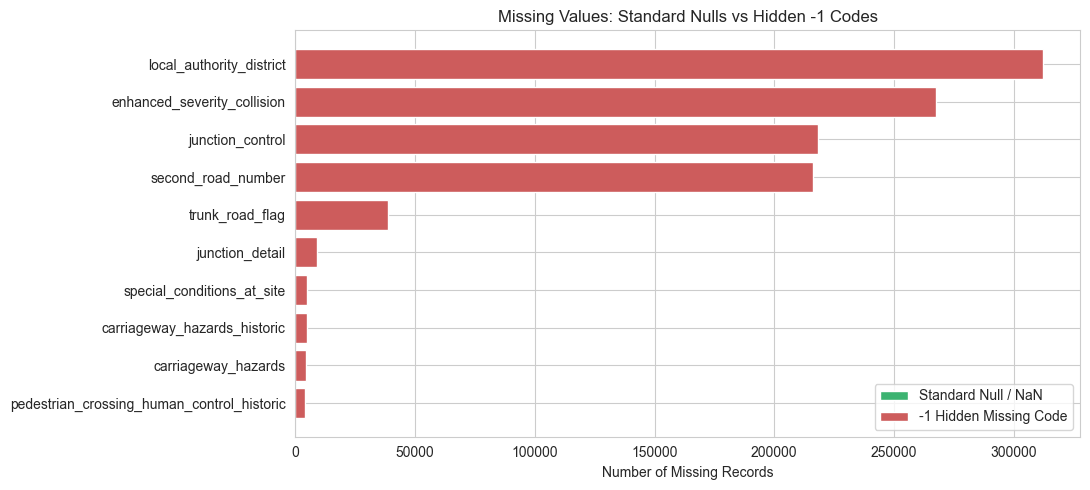

In [9]:
top10_plot = top_missing.head(10).sort_values(by='total_missing', ascending=True)

plt.figure(figsize=(11, 5))
plt.barh(top10_plot.index, top10_plot['null_count'], color='mediumseagreen', label='Standard Null / NaN')
plt.barh(top10_plot.index, top10_plot['minus_one_count'], left=top10_plot['null_count'], color='indianred', label='-1 Hidden Missing Code')

plt.title('Missing Values: Standard Nulls vs Hidden -1 Codes')
plt.xlabel('Number of Missing Records')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [10]:
# check for missing or out-of-bounds coordinates
bad_lat = df_5yr['latitude'].isnull() | (df_5yr['latitude'] < 49.8) | (df_5yr['latitude'] > 60.9)
bad_lon = df_5yr['longitude'].isnull() | (df_5yr['longitude'] < -8.6) | (df_5yr['longitude'] > 1.8)
bad_coords = bad_lat | bad_lon

print(f"Total rows before cleaning: {len(df_5yr):,}")
print(f"Rows with invalid or missing coordinates: {bad_coords.sum()}")

# show a few examples of bad coordinates
df_5yr.loc[bad_coords, ['collision_index', 'latitude', 'longitude', 'collision_year']].head()

Total rows before cleaning: 520,084
Rows with invalid or missing coordinates: 93


,collision_index,latitude,longitude,collision_year
393,2019121901588,NaN,NaN,2019
9211,202063A035620,NaN,NaN,2020
11257,2021122200049,NaN,NaN,2021
15971,20191367G1635,NaN,NaN,2019
18063,2021052101361,NaN,NaN,2021


In [11]:
# drop rows with bad coordinates
df_5yr = df_5yr[~bad_coords].copy()

# verify that no invalid coordinates remain
remaining_bad_lat = (df_5yr['latitude'].isnull() | (df_5yr['latitude'] < 49.8) | (df_5yr['latitude'] > 60.9)).sum()
remaining_bad_lon = (df_5yr['longitude'].isnull() | (df_5yr['longitude'] < -8.6) | (df_5yr['longitude'] > 1.8)).sum()

print("Remaining bad latitude values:", remaining_bad_lat)
print("Remaining bad longitude values:", remaining_bad_lon)
print(f"Dataset rows after cleaning coordinates: {len(df_5yr):,} (93 rows dropped)")

Remaining bad latitude values: 0
Remaining bad longitude values: 0
Dataset rows after cleaning coordinates: 519,991 (93 rows dropped)


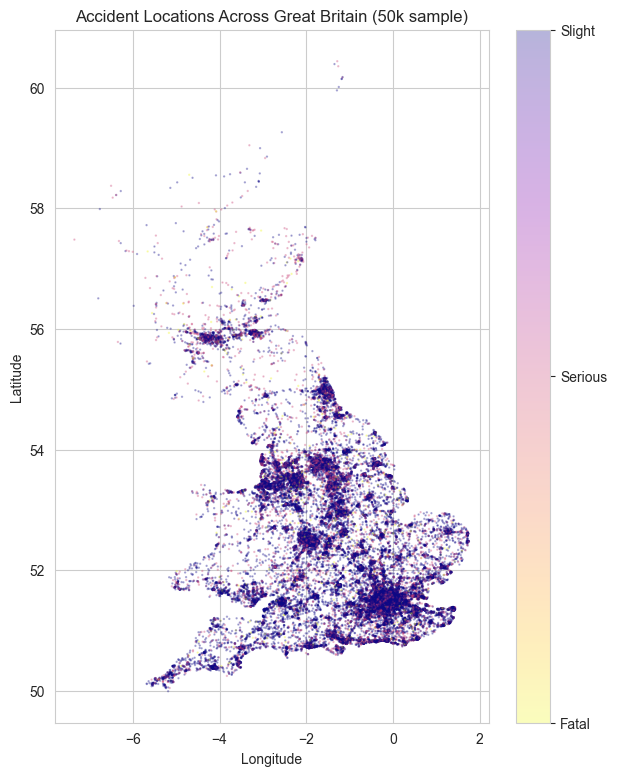

In [12]:
# sample 50,000 rows so the plot doesn't take forever to render
sample_coords = df_5yr.sample(50000, random_state=42)

plt.figure(figsize=(7, 9))
plt.scatter(sample_coords['longitude'], sample_coords['latitude'], 
            c=sample_coords['collision_severity'], cmap='plasma_r', 
            s=0.5, alpha=0.3)
plt.title('Accident Locations Across Great Britain (50k sample)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
cbar = plt.colorbar()
cbar.set_ticks([1, 2, 3])
cbar.set_ticklabels(['Fatal', 'Serious', 'Slight'])
plt.show()

In [13]:
# check value counts of speed limit
legal_limits = [20, 30, 40, 50, 60, 70]
invalid_speed = ~df_5yr['speed_limit'].isin(legal_limits)

print("Number of invalid speed limit rows:", invalid_speed.sum())
print("\nSpeed limit counts:")
print(df_5yr['speed_limit'].value_counts(dropna=False).sort_index())

Number of invalid speed limit rows: 92

Speed limit counts:
speed_limit
-1.0         92
 20.0     72093
 30.0    288921
 40.0     44793
 50.0     21868
 60.0     63182
 70.0     29042
Name: count, dtype: int64


In [14]:
# calculate median speed limit for each combination of area and road type from valid records
valid_speeds = df_5yr[~invalid_speed]
speed_medians = valid_speeds.groupby(['urban_or_rural_area', 'road_type'])['speed_limit'].median()
print("Median speed limit by area and road type:")
print(speed_medians)

# create a flag column
df_5yr['speed_limit_imputed'] = 0

# fill missing speed limits using the group median
for (area, r_type), med_speed in speed_medians.items():
    mask = invalid_speed & (df_5yr['urban_or_rural_area'] == area) & (df_5yr['road_type'] == r_type)
    df_5yr.loc[mask, 'speed_limit'] = med_speed
    df_5yr.loc[mask, 'speed_limit_imputed'] = 1

# if any rows still don't have a valid limit, fill with 30 mph as fallback
remaining_invalid = ~df_5yr['speed_limit'].isin(legal_limits)
df_5yr.loc[remaining_invalid, 'speed_limit'] = 30.0
df_5yr.loc[remaining_invalid, 'speed_limit_imputed'] = 1

print(f"\nTotal speed limit values imputed: {df_5yr['speed_limit_imputed'].sum()}")
print("Remaining invalid speed limits:", (~df_5yr['speed_limit'].isin(legal_limits)).sum())

Median speed limit by area and road type:


urban_or_rural_area  road_type
1                    1            30.0
                     2            30.0
                     3            30.0
                     6            30.0
                     7            30.0
                     9            30.0
2                    1            40.0
                     2            30.0
                     3            70.0
                     6            50.0
                     7            70.0
                     9            30.0
Name: speed_limit, dtype: float64

Total speed limit values imputed: 92
Remaining invalid speed limits: 0


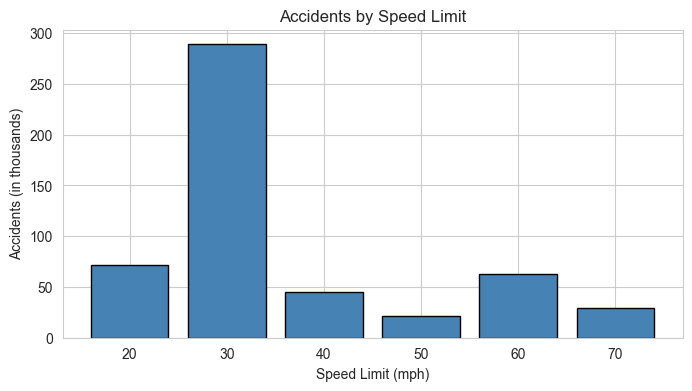

In [15]:
plt.figure(figsize=(8, 4))
speed_counts = df_5yr['speed_limit'].value_counts().sort_index()

plt.bar([str(int(s)) for s in speed_counts.index], speed_counts.values / 1000, color='steelblue', edgecolor='black')
plt.title('Accidents by Speed Limit')
plt.xlabel('Speed Limit (mph)')
plt.ylabel('Accidents (in thousands)')
plt.show()

In [16]:
# parse date column
df_5yr['date_parsed'] = pd.to_datetime(df_5yr['date'], format='%d/%m/%Y')

print("Date parsing completed:")
print("Earliest date:", df_5yr['date_parsed'].min().strftime('%Y-%m-%d'))
print("Latest date:  ", df_5yr['date_parsed'].max().strftime('%Y-%m-%d'))
print("Unparseable dates:", df_5yr['date_parsed'].isnull().sum())

Date parsing completed:
Earliest date: 2019-01-01
Latest date:   2023-12-31
Unparseable dates: 0


In [17]:
# split time string by colon
time_parts = df_5yr['time'].str.split(':', expand=True)

df_5yr['collision_hour'] = pd.to_numeric(time_parts[0], errors='coerce')
df_5yr['collision_minute'] = pd.to_numeric(time_parts[1], errors='coerce')

print("Missing hours:", df_5yr['collision_hour'].isnull().sum())

# fill missing hour with 12 and minute with 0
df_5yr['collision_hour'] = df_5yr['collision_hour'].fillna(12).astype(int)
df_5yr['collision_minute'] = df_5yr['collision_minute'].fillna(0).astype(int)

# verify all hours are 0-23 and minutes are 0-59
print("Hour range:", df_5yr['collision_hour'].min(), "to", df_5yr['collision_hour'].max())
print("Minute range:", df_5yr['collision_minute'].min(), "to", df_5yr['collision_minute'].max())

Missing hours: 0
Hour range: 0 to 23
Minute range: 0 to 59


In [18]:
# 1. Check duplicate primary keys
pk_duplicates = df_5yr['collision_index'].duplicated().sum()
print("1. Duplicate collision_index count:", pk_duplicates)

# 2. Check exact duplicate rows
exact_duplicates = df_5yr.duplicated().sum()
print("2. Exact duplicate rows count:", exact_duplicates)

# 3. Check records with same date, time, and coordinates
same_spot_time = df_5yr.duplicated(subset=['date', 'time', 'latitude', 'longitude'], keep=False).sum()
print(f"3. Records sharing identical date, time, and coordinates: {same_spot_time:,} ({same_spot_time / len(df_5yr) * 100:.2f}%)")

# look at an example cluster
sample_cluster = df_5yr[df_5yr.duplicated(subset=['date', 'time', 'latitude', 'longitude'], keep=False)][
    ['collision_index', 'date', 'time', 'number_of_vehicles', 'number_of_casualties', 'collision_severity']
].sort_values(by=['date', 'time']).head(4)
print("\nExample of multiple records at the same spot:")
print(sample_cluster)

1. Duplicate collision_index count: 0


2. Exact duplicate rows count: 0


3. Records sharing identical date, time, and coordinates: 14 (0.00%)



Example of multiple records at the same spot:
       collision_index        date   time  number_of_vehicles  \
314186   20201379J0992  19/09/2020  13:54                   3   
358156   20201379J0092  19/09/2020  13:54                   3   
34332    2022070855036  21/11/2022  07:25                   2   
235714   2022070855519  21/11/2022  07:25                   3   

        number_of_casualties  collision_severity  
314186                     3                   2  
358156                     3                   3  
34332                      2                   3  
235714                     3                   3  


In [19]:
# check for values less than 1
zero_vehicles = (df_5yr['number_of_vehicles'] < 1).sum()
zero_casualties = (df_5yr['number_of_casualties'] < 1).sum()

print("Records with number_of_vehicles < 1:", zero_vehicles)
print("Records with number_of_casualties < 1:", zero_casualties)

# show summary statistics
df_5yr[['number_of_vehicles', 'number_of_casualties']].describe()

Records with number_of_vehicles < 1: 0
Records with number_of_casualties < 1: 0


,number_of_vehicles,number_of_casualties
count,519991.000000,519991.000000
mean,1.833457,1.279432
std,0.689678,0.712260
min,1.000000,1.000000
25%,1.000000,1.000000
50%,2.000000,1.000000
75%,2.000000,1.000000
max,17.000000,70.000000


In [20]:
# count of each severity level
severity_counts = df_5yr['collision_severity'].value_counts().sort_index()
severity_pcts = (severity_counts / len(df_5yr)) * 100

target_summary = pd.DataFrame({
    'severity_code': severity_counts.index,
    'severity_label': ['Fatal', 'Serious', 'Slight'],
    'accident_count': severity_counts.values,
    'percentage': severity_pcts.values
})
print("Target variable distribution:")
print(target_summary)

Target variable distribution:
   severity_code severity_label  accident_count  percentage
0              1          Fatal            7646    1.470410
1              2        Serious          109369   21.032864
2              3         Slight          402976   77.496726


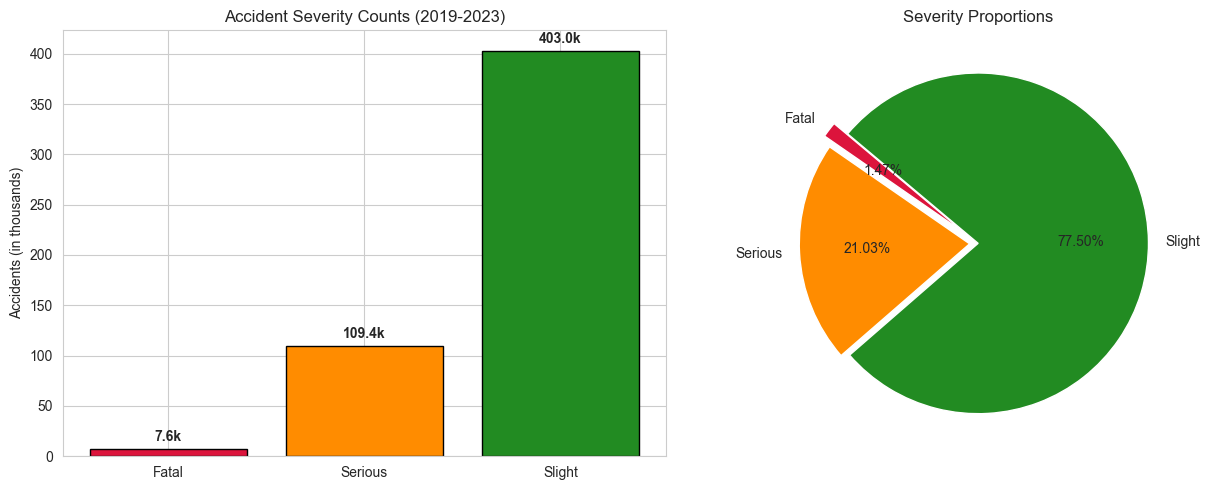

In [21]:
plt.figure(figsize=(13, 5))

# Bar chart
plt.subplot(1, 2, 1)
bars = plt.bar(target_summary['severity_label'], target_summary['accident_count'] / 1000, 
               color=['crimson', 'darkorange', 'forestgreen'], edgecolor='black')
plt.title('Accident Severity Counts (2019-2023)')
plt.ylabel('Accidents (in thousands)')
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y + 5, f"{y:.1f}k", ha='center', va='bottom', fontweight='bold')

# Pie chart
plt.subplot(1, 2, 2)
plt.pie(target_summary['accident_count'], labels=target_summary['severity_label'], 
        autopct='%.2f%%', colors=['crimson', 'darkorange', 'forestgreen'], 
        explode=[0.1, 0.05, 0], startangle=140)
plt.title('Severity Proportions')

plt.tight_layout()
plt.show()

In [22]:
# month and day of month
df_5yr['collision_month'] = df_5yr['date_parsed'].dt.month
df_5yr['collision_day'] = df_5yr['date_parsed'].dt.day

# month name
month_names = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun',
               7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}
df_5yr['collision_month_name'] = df_5yr['collision_month'].map(month_names)

# day of week name (in STATS19: 1 = Sunday, 2 = Monday, ..., 7 = Saturday)
day_names = {1: 'Sunday', 2: 'Monday', 3: 'Tuesday', 4: 'Wednesday', 5: 'Thursday', 6: 'Friday', 7: 'Saturday'}
df_5yr['day_of_week_name'] = df_5yr['day_of_week'].map(day_names)

# weekend flag
df_5yr['is_weekend'] = df_5yr['day_of_week'].isin([1, 7]).astype(int)

# check a few rows
df_5yr[['date_parsed', 'collision_month_name', 'day_of_week_name', 'is_weekend']].head()

,date_parsed,collision_month_name,day_of_week_name,is_weekend
0,2019-05-16,May,Thursday,0
1,2019-06-11,Jun,Tuesday,0
2,2019-08-28,Aug,Wednesday,0
3,2019-10-25,Oct,Friday,0
4,2019-06-20,Jun,Thursday,0


In [23]:
def assign_time_band(hour):
    if 7 <= hour < 10:
        return 'Morning Peak (07:00-09:59)'
    elif 10 <= hour < 16:
        return 'Daytime (10:00-15:59)'
    elif 16 <= hour < 19:
        return 'Evening Peak (16:00-18:59)'
    else:
        return 'Night / Off-Peak (19:00-06:59)'

df_5yr['time_of_day_band'] = df_5yr['collision_hour'].apply(assign_time_band)

print("Accidents by time-of-day band:")
print(df_5yr['time_of_day_band'].value_counts())

Accidents by time-of-day band:
time_of_day_band
Daytime (10:00-15:59)             186544
Night / Off-Peak (19:00-06:59)    131704
Evening Peak (16:00-18:59)        124444
Morning Peak (07:00-09:59)         77299
Name: count, dtype: int64


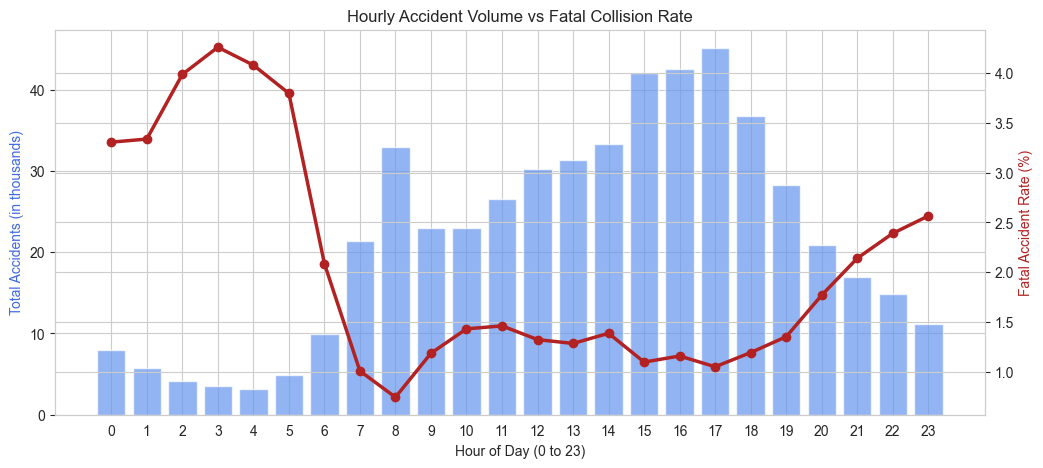

In [24]:
# calculate total accidents and fatal rate by hour
hourly_stats = df_5yr.groupby('collision_hour').agg(
    total_accidents=('collision_severity', 'count'),
    fatal_accidents=('collision_severity', lambda s: (s == 1).sum())
)
hourly_stats['fatal_rate_pct'] = (hourly_stats['fatal_accidents'] / hourly_stats['total_accidents']) * 100

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

ax1.bar(hourly_stats.index, hourly_stats['total_accidents'] / 1000, color='cornflowerblue', alpha=0.7, label='Accidents (Thousands)')
ax2.plot(hourly_stats.index, hourly_stats['fatal_rate_pct'], color='firebrick', marker='o', linewidth=2.5, label='Fatal Rate (%)')

ax1.set_xlabel('Hour of Day (0 to 23)')
ax1.set_ylabel('Total Accidents (in thousands)', color='royalblue')
ax2.set_ylabel('Fatal Accident Rate (%)', color='firebrick')
plt.title('Hourly Accident Volume vs Fatal Collision Rate')
plt.xticks(range(0, 24))
plt.show()

In [25]:
# dictionaries based on the official STATS19 guidance
severity_dict = {1: 'Fatal', 2: 'Serious', 3: 'Slight'}
road_type_dict = {1: 'Roundabout', 2: 'One way street', 3: 'Dual carriageway', 6: 'Single carriageway', 7: 'Slip road', 9: 'Unknown', 12: 'One way street/Slip road', -1: 'Missing / Unknown'}
light_dict = {1: 'Daylight', 4: 'Darkness - lights lit', 5: 'Darkness - lights unlit', 6: 'Darkness - no lighting', 7: 'Darkness - lighting unknown', -1: 'Missing / Unknown'}
weather_dict = {1: 'Fine no high winds', 2: 'Raining no high winds', 3: 'Snowing no high winds', 4: 'Fine + high winds', 5: 'Raining + high winds', 6: 'Snowing + high winds', 7: 'Fog or mist', 8: 'Other', 9: 'Unknown', -1: 'Missing / Unknown'}
surface_dict = {1: 'Dry', 2: 'Wet or damp', 3: 'Snow', 4: 'Frost or ice', 5: 'Flood over 3cm deep', 6: 'Oil or diesel', 7: 'Mud', 9: 'Unknown', -1: 'Missing / Unknown'}
urban_rural_dict = {1: 'Urban', 2: 'Rural', 3: 'Unallocated', -1: 'Missing / Unknown'}
road_class_dict = {1: 'Motorway', 2: 'A(M)', 3: 'A', 4: 'B', 5: 'C', 6: 'Unclassified', -1: 'Missing / Unknown'}
junction_dict = {0: 'Not at junction', 1: 'Roundabout', 2: 'Mini-roundabout', 3: 'T or staggered junction', 5: 'Slip road', 6: 'Crossroads', 7: 'More than 4 arms', 8: 'Private drive or entrance', 9: 'Other junction', -1: 'Missing / Unknown'}
control_dict = {0: 'Not at junction', 1: 'Authorised person', 2: 'Auto traffic signal', 3: 'Stop sign', 4: 'Give way or uncontrolled', -1: 'Missing / Unknown'}
crossing_dict = {0: 'No physical facility within 50m', 1: 'Zebra', 4: 'Pelican/puffin/toucan', 5: 'Pedestrian phase at signals', 7: 'Footbridge or subway', 8: 'Central refuge', -1: 'Missing / Unknown'}
special_cond_dict = {0: 'None', 1: 'Auto traffic signal out', 2: 'Auto signal defective', 3: 'Road sign/marking defective', 4: 'Roadworks', 5: 'Road surface defective', 6: 'Oil or diesel', 7: 'Mud', -1: 'Missing / Unknown'}
hazards_dict = {0: 'None', 1: 'Dislodged load in road', 2: 'Other object in road', 3: 'Previous accident', 6: 'Dog on road', 7: 'Other animal on road', 9: 'Pedestrian in road', -1: 'Missing / Unknown'}
trunk_dict = {1: 'Trunk road', 2: 'Non-trunk road', -1: 'Missing / Unknown'}

# create decoded label columns
df_5yr['collision_severity_label'] = df_5yr['collision_severity'].map(severity_dict)
df_5yr['road_type_label'] = df_5yr['road_type'].map(road_type_dict).fillna('Missing / Unknown')
df_5yr['light_conditions_label'] = df_5yr['light_conditions'].map(light_dict).fillna('Missing / Unknown')
df_5yr['weather_conditions_label'] = df_5yr['weather_conditions'].map(weather_dict).fillna('Missing / Unknown')
df_5yr['road_surface_conditions_label'] = df_5yr['road_surface_conditions'].map(surface_dict).fillna('Missing / Unknown')
df_5yr['urban_or_rural_area_label'] = df_5yr['urban_or_rural_area'].map(urban_rural_dict).fillna('Missing / Unknown')
df_5yr['first_road_class_label'] = df_5yr['first_road_class'].map(road_class_dict).fillna('Missing / Unknown')
df_5yr['junction_detail_label'] = df_5yr['junction_detail'].map(junction_dict).fillna('Missing / Unknown')
df_5yr['junction_control_label'] = df_5yr['junction_control'].map(control_dict).fillna('Missing / Unknown')
df_5yr['pedestrian_crossing_label'] = df_5yr['pedestrian_crossing'].map(crossing_dict).fillna('Missing / Unknown')
df_5yr['special_conditions_at_site_label'] = df_5yr['special_conditions_at_site'].map(special_cond_dict).fillna('Missing / Unknown')
df_5yr['carriageway_hazards_label'] = df_5yr['carriageway_hazards'].map(hazards_dict).fillna('Missing / Unknown')
df_5yr['trunk_road_flag_label'] = df_5yr['trunk_road_flag'].map(trunk_dict).fillna('Missing / Unknown')

print("Categories mapped successfully! Sample:")
df_5yr[['collision_severity', 'collision_severity_label', 'weather_conditions_label', 'road_type_label']].head()

Categories mapped successfully! Sample:


,collision_severity,collision_severity_label,weather_conditions_label,road_type_label
0,3,Slight,Fine no high winds,One way street
1,3,Slight,Fine no high winds,Single carriageway
2,2,Serious,Fine no high winds,Single carriageway
3,3,Slight,Fine no high winds,Dual carriageway
4,3,Slight,Fine no high winds,Roundabout


In [26]:
# list of columns to drop
columns_to_drop = [
    # data leakage columns
    'enhanced_severity_collision',
    'collision_injury_based',
    'collision_adjusted_severity_serious',
    'collision_adjusted_severity_slight',
    'did_police_officer_attend_scene_of_accident',
    
    # redundant identifiers and coordinates
    'collision_ref_no',
    'location_easting_osgr',
    'location_northing_osgr',
    
    # deprecated historic columns
    'junction_detail_historic',
    'pedestrian_crossing_human_control_historic',
    'pedestrian_crossing_physical_facilities_historic',
    'special_conditions_at_site_historic',
    'carriageway_hazards_historic',
    
    # high missingness or too many categories
    'local_authority_district',
    'local_authority_highway',
    'local_authority_highway_current',
    'local_authority_ons_district',
    'first_road_number',
    'second_road_class',
    'second_road_number',
    'lsoa_of_accident_location'
]

# drop the columns
cols_to_remove = [col for col in columns_to_drop if col in df_5yr.columns]
df_final = df_5yr.drop(columns=cols_to_remove).copy()

print(f"Original columns: {df_5yr.shape[1]}")
print(f"Dropped columns:  {len(cols_to_remove)}")
print(f"Final columns:    {df_final.shape[1]}")
print("Final dataset shape:", df_final.shape)

Original columns: 67
Dropped columns:  20
Final columns:    47
Final dataset shape: (519991, 47)


In [27]:
processed_csv = 'data/processed/cleaned_collisions_2019_2023.csv'
processed_parquet = 'data/processed/cleaned_collisions_2019_2023.parquet'

print("Saving cleaned CSV...")
df_final.to_csv(processed_csv, index=False)

print("Saving cleaned Parquet...")
df_final.to_parquet(processed_parquet, index=False)

print("Done saving!")
print(f"CSV size:     {os.path.getsize(processed_csv) / (1024**2):.2f} MB")
print(f"Parquet size: {os.path.getsize(processed_parquet) / (1024**2):.2f} MB")

Saving cleaned CSV...


Saving cleaned Parquet...


Done saving!
CSV size:     163.41 MB
Parquet size: 21.05 MB


In [28]:
# remove temporary intermediate files
if os.path.exists(staging_file):
    os.remove(staging_file)
    print(f"Removed staging file: {staging_file}")
else:
    print("No staging file found.")

Removed staging file: data/intermediate/staged_raw_2019_2023.csv
